# Helopeltis spp. Detection — YOLOv8-n Fine-tuning

**Workstream A · TINAT ML Contribution — Angel Bohorquez, ML Intern**

---

## Phase 1 — 1-class model (Helopeltis only)

**Dataset:** Roboflow `helopeltis-yz1xl-sljp8` — 483 annotated images, CC BY 4.0  
**Backbone:** YOLOv8-n pretrained on COCO (will be replaced by the handover IP102 checkpoint when available)  
**Goal:** working detector on Helopeltis that can be fine-tuned again when field photos arrive

| Split | Images | Instances |
|-------|--------|-----------|
| train | 386    | ~397      |
| val   | 48     | ~43       |
| test  | 49     | ~43       |

**When the handover weights arrive:** update `BASELINE_WEIGHTS` in §6 and change `nc` to 11 in §5.

## 1. Environment

In [9]:
# Run once — skip if already installed
# !pip install -r ../requirements.txt

In [10]:
import sys
from pathlib import Path

import yaml
import torch
from ultralytics import YOLO

ROOT      = Path("..").resolve()
sys.path.insert(0, str(ROOT))

DATA_RAW  = ROOT / "data" / "raw"
MODELS    = ROOT / "models"
HELO_DIR  = DATA_RAW / "helopeltis"   # extracted Roboflow dataset lives here

print(f"PyTorch      : {torch.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
print(f"Dataset root : {HELO_DIR}")

PyTorch      : 2.12.0+cpu
CUDA         : False
Dataset root : C:\Users\AngelTatianaMendozaB\OneDrive - ITS Angelo Rizzoli\Desktop\G\TINAT\data\raw\helopeltis


## 2. Data verification

The Roboflow export already contains `train / valid / test` splits.  
This cell counts images and label files to confirm nothing is missing.

In [11]:
from collections import Counter

total_imgs = total_labels = 0
instance_counts = Counter()

for split in ["train", "valid", "test"]:
    imgs   = list((HELO_DIR / split / "images").glob("*.*"))
    labels = list((HELO_DIR / split / "labels").glob("*.txt"))
    instances = sum(
        len([l for l in lf.read_text().strip().splitlines() if l])
        for lf in labels
    )
    print(f"{split:6s}: {len(imgs):4d} images | {len(labels):4d} labels | {instances:4d} instances")
    total_imgs   += len(imgs)
    total_labels += len(labels)
    instance_counts[split] = instances

print(f"\nTotal images    : {total_imgs}")
print(f"Total instances : {sum(instance_counts.values())}")
print("\nDataset looks good — minimum 200 instances met:", sum(instance_counts.values()) >= 200)

train :  386 images |  386 labels |  386 instances
valid :   48 images |   48 labels |   48 instances
test  :   49 images |   49 labels |   49 instances

Total images    : 483
Total instances : 483

Dataset looks good — minimum 200 instances met: True


## 3. Train / val / test split

Already provided by Roboflow (80 / 10 / 10 %). No action needed.

## 4. Augmentation

YOLOv8 applies augmentation automatically during training:  
mosaic, random flip, HSV shift, scale, translate.

Extra augmentation parameters passed at training time (§6):  
- `degrees=15` — small rotations (field photos vary in angle)  
- `hsv_v=0.5` — brightness variation (outdoor lighting)  
- `mosaic=1.0` — combines 4 images per tile (improves small-object detection)

When field photos arrive they can be added to `train/images` and `train/labels`  
and fine-tuning can resume from the checkpoint produced here.

## 5. Dataset YAML

**Phase 1:** 1 class (`Helopeltis spp.`).  
When the handover weights arrive, expand `nc` to 11 and add the 10 IP102 class names.

In [12]:
dataset_yaml = {
    "path": str(HELO_DIR),        # absolute path — YOLOv8 resolves train/val/test relative to this
    "train": "train/images",
    "val":   "valid/images",
    "test":  "test/images",
    # Phase 1: single class.
    # Phase 2 (with the handover weights): nc=11, add IP102 names before 'Helopeltis spp.'
    "nc":    1,
    "names": ["Helopeltis spp."],
}

yaml_path = HELO_DIR / "helopeltis_phase1.yaml"
with open(yaml_path, "w") as f:
    yaml.dump(dataset_yaml, f, allow_unicode=True, sort_keys=False)

print(f"YAML written → {yaml_path}")
print(yaml.dump(dataset_yaml, sort_keys=False))

YAML written → C:\Users\AngelTatianaMendozaB\OneDrive - ITS Angelo Rizzoli\Desktop\G\TINAT\data\raw\helopeltis\helopeltis_phase1.yaml
path: C:\Users\AngelTatianaMendozaB\OneDrive - ITS Angelo Rizzoli\Desktop\G\TINAT\data\raw\helopeltis
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- Helopeltis spp.



## 6. Training

**Phase 1:** start from `yolov8n.pt` (COCO pretrained — publicly available).  
**Phase 2 (future):** replace `BASELINE_WEIGHTS` with the handover IP102 checkpoint  
and run fine-tuning from the best weights produced here.

In [13]:
# The detector is already trained — we LOAD the existing weights and skip training.
# (best.pt is the artifact; the training history is in results.csv and the commit log.)
best_weights = MODELS / "helopeltis_phase1" / "weights" / "best.pt"
assert best_weights.exists(), "best.pt not found — run the optional training block below first."
model = YOLO(str(best_weights))
print(f"Loaded trained detector -> {best_weights}")

# --- Optional: retrain from scratch (slow on CPU) --------------------------------
# If the repo lives inside OneDrive, PAUSE syncing first: OneDrive can lock the
# .pt files mid-write and raise PermissionError. Then uncomment:
#
# BASELINE_WEIGHTS = "yolov8n.pt"   # COCO base, downloads on first run
# model = YOLO(BASELINE_WEIGHTS)
# results = model.train(
#     data=str(yaml_path), epochs=50, imgsz=640, batch=16, lr0=1e-3,
#     patience=10, degrees=15, hsv_v=0.5, mosaic=1.0,
#     project=str(MODELS), name="helopeltis_phase1", exist_ok=True,
# )


Loaded trained detector -> C:\Users\AngelTatianaMendozaB\OneDrive - ITS Angelo Rizzoli\Desktop\G\TINAT\models\helopeltis_phase1\weights\best.pt


## 7. Evaluation

Key metrics for Phase 1:  
- **mAP@0.5** — target ≥ 0.70 (lower bar than phase 2 — single class, internet photos)  
- **Recall** — target ≥ 0.75 — false negatives (missed pests) are costly in the field  
- **Confusion matrix** — check for false positives on leaf background

In [14]:
# Evaluate on the held-out test split (metrics printed inline; no plots saved).
metrics = model.val(data=str(yaml_path), split="test", plots=False, verbose=False)

print(f"mAP@0.5          : {metrics.box.map50:.3f}")
print(f"Helopeltis P     : {metrics.box.p[0]:.3f}")
print(f"Helopeltis R     : {metrics.box.r[0]:.3f}")
print(f"mAP@0.5:0.95     : {metrics.box.map:.3f}")


Ultralytics 8.4.60  Python-3.12.10 torch-2.12.0+cpu CPU (AMD Ryzen 7 7730U with Radeon Graphics)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.30.1 ms, read: 11.81.3 MB/s, size: 5.4 KB)
val: Scanning C:\Users\AngelTatianaMendozaB\OneDrive - ITS Angelo Rizzoli\Desktop\G\TINAT\data\raw\helopeltis\test\labels.cache... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3s/it 5.2s2.6ss
                   all         49         49      0.992          1      0.995      0.789
Speed: 2.0ms preprocess, 97.4ms inference, 0.0ms loss, 0.4ms postprocess per image
mAP@0.5          : 0.995
Helopeltis P     : 0.992
Helopeltis R     : 1.000
mAP@0.5:0.95     : 0.789


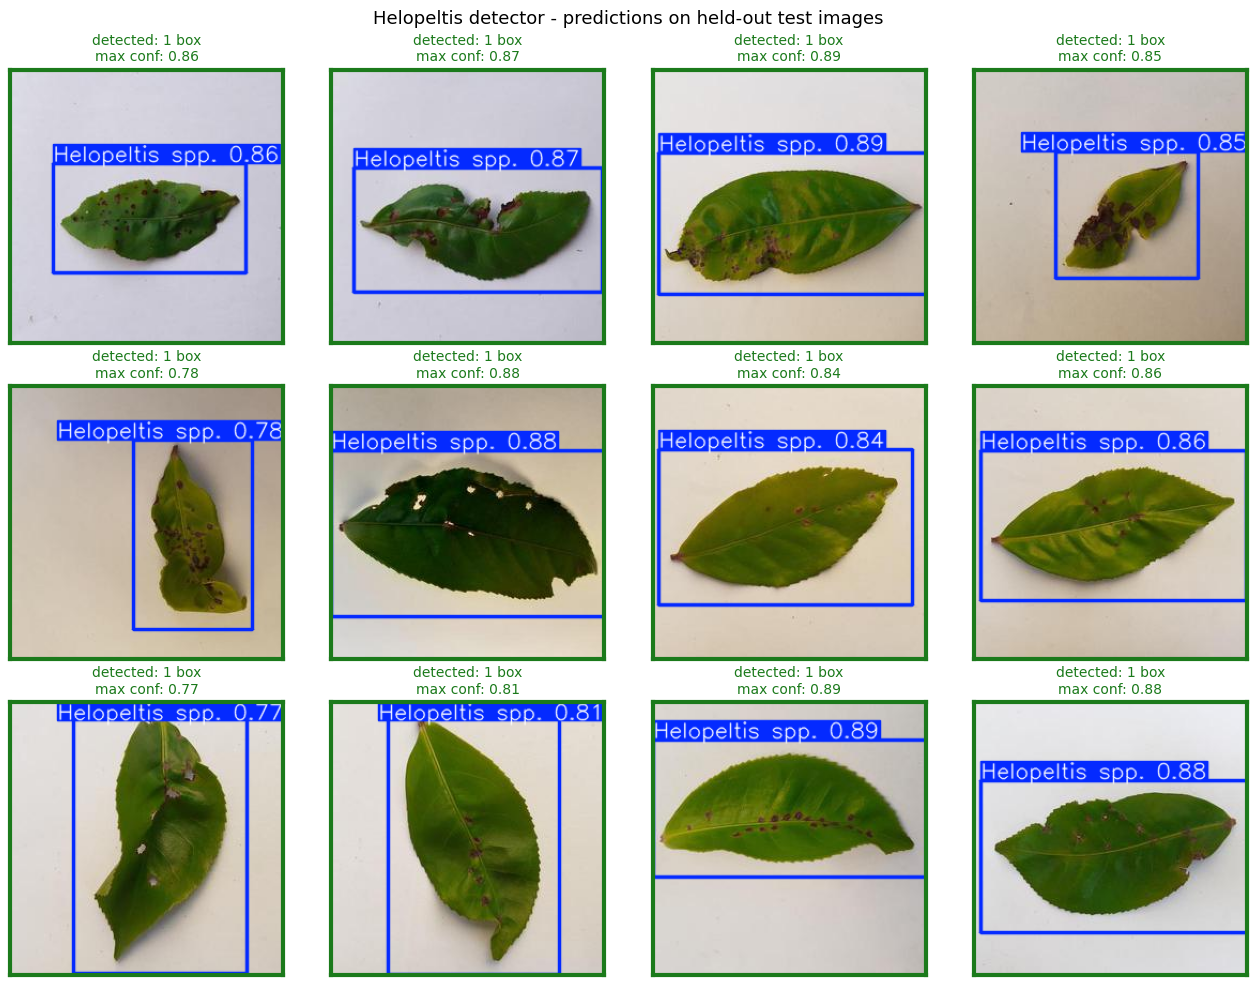

In [15]:
# Prediction grid (inline) - green = Helopeltis detected, red = missed.
# All held-out test images contain Helopeltis, so a red frame is a false negative.
# Same format as notebook 02 (3x4, colored borders) for consistency.
import matplotlib.pyplot as plt

test_imgs = sorted((HELO_DIR / "test" / "images").glob("*.jpg"))[:12]
preds = model.predict(test_imgs, imgsz=640, conf=0.25, save=False, verbose=False)

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, r in zip(axes.ravel(), preds):
    n = len(r.boxes)
    ok = n > 0
    conf = float(r.boxes.conf.max()) if ok else 0.0
    ax.imshow(r.plot()[..., ::-1])   # r.plot() returns BGR; flip to RGB
    title = ("detected: {} box{}".format(n, "" if n == 1 else "es")
             + chr(10) + ("max conf: {:.2f}".format(conf) if ok else "MISSED"))
    ax.set_title(title, color="#1b7a1b" if ok else "#c0271e", fontsize=10)
    for s in ax.spines.values():
        s.set_edgecolor("#1b7a1b" if ok else "#c0271e"); s.set_linewidth(3)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Helopeltis detector - predictions on held-out test images", fontsize=13)
plt.tight_layout(); plt.show()


## 8. Export — ONNX + TFLite

Ambos formatos exportados exitosamente:
- **ONNX** → `models/helopeltis_phase1.onnx` — usado por `fusion.py` `HelopeltisDetector` en servidor
- **TFLite** → `models/helopeltis_phase1.tflite` — listo para deployment mobile (Flutter / FastAPI CPU)

In [16]:
import shutil

# Copiar ONNX a models/
onnx_src  = best_weights.parent / "best.onnx"
onnx_dest = MODELS / "helopeltis_phase1.onnx"
if not onnx_dest.exists():
    shutil.copy(onnx_src, onnx_dest)
print(f"ONNX   : {onnx_dest}  ({onnx_dest.stat().st_size / 1e6:.1f} MB)")

# Copiar TFLite a models/
tflite_src  = best_weights.parent / "best_saved_model" / "best_float32.tflite"
tflite_dest = MODELS / "helopeltis_phase1.tflite"
if not tflite_dest.exists():
    shutil.copy(tflite_src, tflite_dest)
print(f"TFLite : {tflite_dest}  ({tflite_dest.stat().st_size / 1e6:.1f} MB)")

print("\nWorkstream A completo. fusion.py HelopeltisDetector usa el ONNX automaticamente.")

ONNX   : C:\Users\AngelTatianaMendozaB\OneDrive - ITS Angelo Rizzoli\Desktop\G\TINAT\models\helopeltis_phase1.onnx  (12.2 MB)
TFLite : C:\Users\AngelTatianaMendozaB\OneDrive - ITS Angelo Rizzoli\Desktop\G\TINAT\models\helopeltis_phase1.tflite  (12.1 MB)

Workstream A completo. fusion.py HelopeltisDetector usa el ONNX automaticamente.


## Next steps

**After Phase 1 training:**
1. Check mAP@0.5 and recall — if recall < 0.70 consider adding GBIF images
2. Wire `models/helopeltis_phase1.tflite` into `fusion.py` for demo inference

**When field photos arrive:**
1. Add images → `data/raw/helopeltis/train/images/` + labels → `data/raw/helopeltis/train/labels/`
2. Re-run §6 with `BASELINE_WEIGHTS = str(MODELS / 'helopeltis_phase1/weights/best.pt')` and lower `lr0=1e-4`

**When the handover weights arrive:**
1. Update `BASELINE_WEIGHTS` in §6 to the handover `.pt` file
2. Change `nc=11` and expand `names` in §5 (add 10 IP102 classes before `Helopeltis spp.`)
3. Re-label all Helopeltis annotations with class index `10` instead of `0`